# Tahoe-100M: well-level tests on the DMSO wells

Uses the pseudobulks written by `tahoe_dmso_check.ipynb` (`cache/tahoe_dmso_pb.npz`, `cache/tahoe_dmso_meta.csv`).
Each of the 14 plates has two DMSO wells; each well holds about 50 cell lines. The cell lines of a well play the role
that the cell types of a well play in Parse.

Three tests, as in the paper:
1. **Well share** (Figure 2A): how much of the difference between the two DMSO wells of a plate comes from the well
   rather than from sampling of cells (two random halves of one well vs halves of the two wells).
2. **DEG floor** (Figure 4E): DEGs between the two DMSO wells, with the 14 plates as replicates (pseudobulk DESeq2).
3. **Shared well noise** (Figure 2B): does the difference between the two DMSO wells of a plate look alike in
   different cell lines? Compared with the same comparison across plates.

In [1]:
import numpy as np, pandas as pd, scipy.sparse as sp
from itertools import combinations
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

OUT = "cache"
M = sp.load_npz(f"{OUT}/tahoe_dmso_pb.npz").tocsr().astype(np.float64)
meta = pd.read_csv(f"{OUT}/tahoe_dmso_meta.csv")
SEED = 0; rng = np.random.default_rng(SEED)
MIN_CELLS_HALF = 100          # min cells per half for a (plate, cell line) to enter the tests
N_GENES = 2000                # genes most expressed across all DMSO cells

# well 1 / well 2 = lower / higher sample id within a plate (the two DMSO wells have consecutive ids)
order = meta.groupby("plate")["sample"].apply(lambda s: sorted(s.unique()))
meta["well"] = [1 + order[p].index(s) for p, s in zip(meta.plate, meta["sample"])]
print(meta.groupby("plate")["sample"].nunique().value_counts().to_dict(), "plates by number of DMSO wells")
cpm_all = np.asarray(M.sum(0)).ravel()
GENES = np.argsort(-cpm_all)[:N_GENES]
print(M.shape, "groups x genes;", meta.n_cells.sum(), "cells;", meta.cell_line.nunique(), "cell lines")
print("median cells per half:", meta.n_cells.median())

{2: 14} plates by number of DMSO wells
(2800, 51496) groups x genes; 2205786 cells; 50 cell lines
median cells per half: 684.0


In [2]:
def thin(x, n, rng):
    """Binomial thinning of a count vector to n total counts."""
    tot = x.sum()
    return x.copy() if tot <= n else rng.binomial(x.astype(np.int64), n / tot).astype(float)

def logcpm(x):
    return np.log1p(x / max(x.sum(), 1) * 1e6)

IDX = {(r.plate, r.cell_line, r.well, r.half): i for i, r in enumerate(meta.itertuples())}
NC = {(r.plate, r.cell_line, r.well, r.half): r.n_cells for r in meta.itertuples()}
units = sorted({(p, c) for p, c, w, h in IDX
                if all(NC.get((p, c, ww, hh), 0) >= MIN_CELLS_HALF for ww in (1, 2) for hh in "AB")})
print(len(units), "plate x cell line units with >= %d cells in every half" % MIN_CELLS_HALF)

def halves(p, c):
    """Four half-pseudobulks (w1A, w1B, w2A, w2B), thinned to the same total counts, log CPM on GENES."""
    X = [M[IDX[(p, c, w, h)]].toarray().ravel() for w in (1, 2) for h in "AB"]
    n = min(x.sum() for x in X)
    return [logcpm(thin(x, n, rng))[GENES] for x in X]

625 plate x cell line units with >= 100 cells in every half


## 1. Well share of the difference between the two DMSO wells

In [3]:
rows = []
for p, c in units:
    a1, b1, a2, b2 = halves(p, c)
    within = (np.sum((a1 - b1) ** 2) + np.sum((a2 - b2) ** 2)) / 2
    between = (np.sum((a1 - b2) ** 2) + np.sum((a2 - b1) ** 2)) / 2
    rows.append(dict(plate=p, cell_line=c, within=within, between=between, share=(between - within) / between))
SHARE = pd.DataFrame(rows)
SHARE.to_csv(f"{OUT}/tahoe_well_share.csv", index=False)
print("well share: median %.2f, IQR %.2f to %.2f, over %d plate x cell line units" %
      (SHARE.share.median(), SHARE.share.quantile(.25), SHARE.share.quantile(.75), len(SHARE)))
print("between / within: median %.2f" % (SHARE.between / SHARE.within).median())
print(SHARE.groupby("plate").share.median().round(2).to_string())

well share: median 0.38, IQR 0.25 to 0.51, over 625 plate x cell line units
between / within: median 1.61
plate
plate1     0.45
plate10    0.41
plate11    0.38
plate12    0.36
plate13    0.36
plate14    0.38
plate2     0.50
plate3     0.28
plate4     0.51
plate5     0.39
plate6     0.58
plate7     0.21
plate8     0.36
plate9     0.24


## 2. DEGs between the two DMSO wells (plates as replicates)
Pseudobulk DESeq2 per cell line, design `~ plate + well`, thresholds as in the paper (adjusted p < 0.05; |log2 fold change| > 0.25, 0.5 and 1). Needs `pip install pydeseq2`.

In [4]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import warnings; warnings.filterwarnings("ignore")

full = {}
for (p, c, w, h), i in IDX.items():
    full[(p, c, w)] = full.get((p, c, w), 0) + M[i].toarray().ravel()
rows = []
for c in sorted(meta.cell_line.unique()):
    plates = sorted(p for p in meta.plate.unique()
                    if all(NC.get((p, c, w, h), 0) >= MIN_CELLS_HALF for w in (1, 2) for h in "AB"))
    if len(plates) < 6:
        continue
    X = np.vstack([full[(p, c, w)] for w in (1, 2) for p in plates]).round().astype(np.int64)
    keep = X.sum(0) >= 10
    names = [f"{p}_w{w}" for w in (1, 2) for p in plates]
    md_ = pd.DataFrame({"plate": [p for w in (1, 2) for p in plates], "well": ["w1"] * len(plates) + ["w2"] * len(plates)}, index=names)
    dds = DeseqDataSet(counts=pd.DataFrame(X[:, keep], index=names), metadata=md_, design="~plate + well", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["well", "w2", "w1"], quiet=True); st.summary()
    r = st.results_df
    sig = r.padj < 0.05
    rows.append(dict(cell_line=c, plates=len(plates), genes=int(keep.sum()),
                     deg_025=int((sig & (r.log2FoldChange.abs() > 0.25)).sum()),
                     deg_05=int((sig & (r.log2FoldChange.abs() > 0.5)).sum()),
                     deg_1=int((sig & (r.log2FoldChange.abs() > 1)).sum())))
    print(rows[-1], flush=True)
DEG = pd.DataFrame(rows)
DEG.to_csv(f"{OUT}/tahoe_dmso_vs_dmso_deg.csv", index=False)
print(DEG[["deg_025", "deg_05", "deg_1"]].describe().round(0).to_string())

{'cell_line': 'CVCL_0023', 'plates': 14, 'genes': 27387, 'deg_025': 979, 'deg_05': 311, 'deg_1': 74}
{'cell_line': 'CVCL_0028', 'plates': 10, 'genes': 19905, 'deg_025': 105, 'deg_05': 48, 'deg_1': 18}
{'cell_line': 'CVCL_0069', 'plates': 14, 'genes': 27812, 'deg_025': 770, 'deg_05': 220, 'deg_1': 32}
{'cell_line': 'CVCL_0099', 'plates': 14, 'genes': 23276, 'deg_025': 585, 'deg_05': 181, 'deg_1': 30}
{'cell_line': 'CVCL_0131', 'plates': 14, 'genes': 28883, 'deg_025': 1512, 'deg_05': 419, 'deg_1': 73}
{'cell_line': 'CVCL_0152', 'plates': 14, 'genes': 25718, 'deg_025': 731, 'deg_05': 165, 'deg_1': 21}
{'cell_line': 'CVCL_0179', 'plates': 14, 'genes': 26429, 'deg_025': 740, 'deg_05': 183, 'deg_1': 22}
{'cell_line': 'CVCL_0218', 'plates': 14, 'genes': 24349, 'deg_025': 656, 'deg_05': 238, 'deg_1': 58}
{'cell_line': 'CVCL_0292', 'plates': 14, 'genes': 24320, 'deg_025': 837, 'deg_05': 246, 'deg_1': 36}
{'cell_line': 'CVCL_0293', 'plates': 14, 'genes': 30148, 'deg_025': 1361, 'deg_05': 524, 'd

## 3. Is the well noise shared across the cell lines of a well?
For each plate and cell line, d = (well 2 minus well 1), log CPM on the same genes. We correlate d between two cell lines
(a) of the same plate, i.e. the same two wells, and (b) of different plates, i.e. different wells.
If (a) > (b), the noise of a well is shared by the cell lines in it. If (b) is also above zero, part of the difference
between the two DMSO wells recurs on every plate (as expected for a fixed position or barcode).

In [5]:
D = {}
for p, c in units:
    a1, b1, a2, b2 = halves(p, c)
    D[(p, c)] = (a2 + b2) / 2 - (a1 + b1) / 2
lines = sorted({c for _, c in D}); plates = sorted({p for p, _ in D})
same, cross = [], []
for c1, c2 in combinations(lines, 2):
    for p in plates:
        if (p, c1) in D and (p, c2) in D:
            same.append(spearmanr(D[(p, c1)], D[(p, c2)])[0])
    for p, q in combinations(plates, 2):
        if (p, c1) in D and (q, c2) in D:
            cross.append(spearmanr(D[(p, c1)], D[(q, c2)])[0])
same, cross = np.array(same), np.array(cross)
print("same plate (same two wells):  median %.3f over %d pairs" % (np.median(same), len(same)))
print("different plates:            median %.3f over %d pairs" % (np.median(cross), len(cross)))
pd.DataFrame({"comparison": ["same plate"] * len(same) + ["different plates"] * len(cross),
              "spearman": np.r_[same, cross]}).to_csv(f"{OUT}/tahoe_shared_noise.csv", index=False)

same plate (same two wells):  median 0.429 over 13649 pairs
different plates:            median 0.241 over 89015 pairs


## 4. Figure

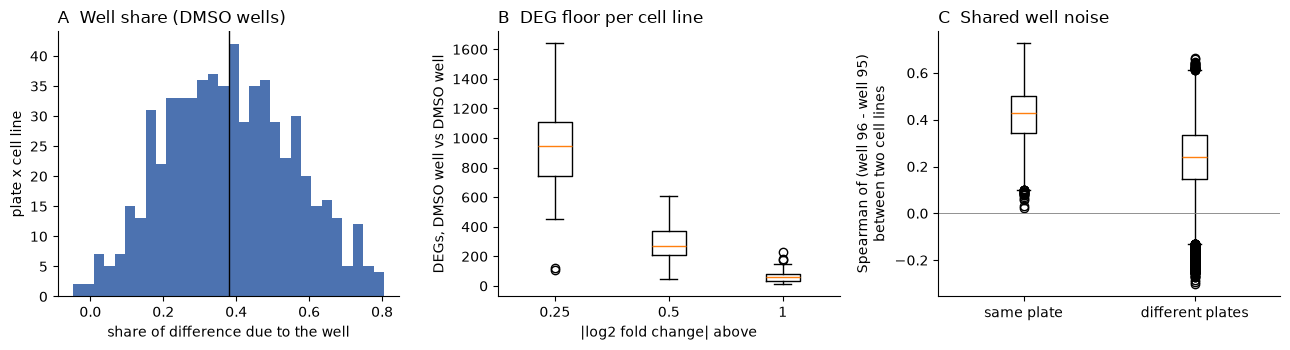

In [8]:
import os; os.makedirs("figures", exist_ok=True)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].hist(SHARE.share, bins=30, color="#4C72B0"); ax[0].axvline(SHARE.share.median(), color="k", lw=1)
ax[0].set_xlabel("share of difference due to the well"); ax[0].set_ylabel("plate x cell line"); ax[0].set_title("A  Well share (DMSO wells)", loc="left")
ax[1].boxplot([DEG.deg_025, DEG.deg_05, DEG.deg_1], tick_labels=["0.25", "0.5", "1"])
ax[1].set_xlabel("|log2 fold change| above"); ax[1].set_ylabel("DEGs, DMSO well vs DMSO well"); ax[1].set_title("B  DEG floor per cell line", loc="left")
ax[2].boxplot([same, cross], tick_labels=["same plate", "different plates"]); ax[2].axhline(0, color="grey", lw=0.6)
ax[2].set_ylabel("Spearman of (well 96 - well 95)\nbetween two cell lines"); ax[2].set_title("C  Shared well noise", loc="left")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/FigTahoe_dmso.png", dpi=300); plt.show()

In [1]:
print(";")

;
